# Notebook 01 — Bicycle model and system identification

Companion to [Chapter 1](../01_vehicle_modelling_and_sysid.md). We build the kinematic
bicycle model, find where friction makes it wrong, and identify the Gazebo car's
parameters from a recorded drive (`../data/sysid.csv`).

In [1]:
import warnings; warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.color': '#e4e3df',
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

## 1. Ackermann geometry
For wheelbase $L$ and track $T$, a turn of radius $R$ (to the rear-axle centre) needs
$\tan\delta_{in} = L/(R-T/2)$ and $\tan\delta_{out} = L/(R+T/2)$.

In [2]:
L, T = 0.254, 0.165          # SAURCON wheelbase and track (m)
for R in (1.0, 2.0, 5.0):
    d_in, d_out, d_bike = np.arctan(L/(R-T/2)), np.arctan(L/(R+T/2)), np.arctan(L/R)
    print(f"R={R:3.1f} m: inner {np.degrees(d_in):5.2f} deg, outer {np.degrees(d_out):5.2f} deg, bicycle {np.degrees(d_bike):5.2f} deg")

R=1.0 m: inner 15.47 deg, outer 13.21 deg, bicycle 14.25 deg
R=2.0 m: inner  7.55 deg, outer  6.95 deg, bicycle  7.24 deg
R=5.0 m: inner  2.96 deg, outer  2.86 deg, bicycle  2.91 deg


## 2. Simulating the kinematic bicycle model
$\dot x = v\cos\psi,\ \dot y = v\sin\psi,\ \dot\psi = v\tan\delta/L$. We add first-order
steering lag $\tau_\delta$ — compare paths for an instant and a lagged steering step.

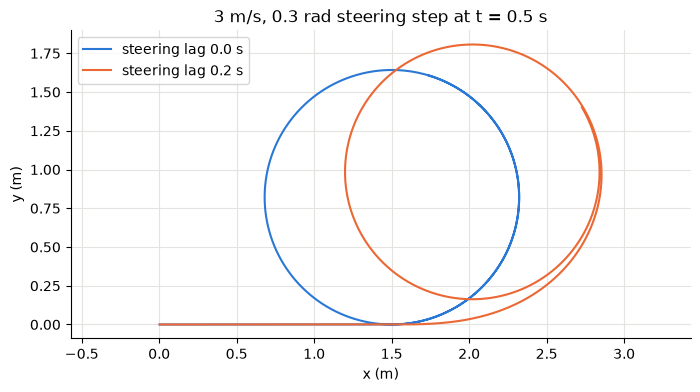

In [3]:
def simulate(v, delta_cmd, tau=0.0, t_end=3.0, dt=0.001):
    x = y = psi = delta = 0.0; path = []
    for k in range(int(t_end/dt)):
        target = delta_cmd if k*dt > 0.5 else 0.0          # step at 0.5 s
        delta += (target - delta) * (1.0 if tau == 0 else min(1, dt/tau))
        psi += v*np.tan(delta)/L*dt
        x += v*np.cos(psi)*dt; y += v*np.sin(psi)*dt
        path.append((x, y))
    return np.array(path)

for tau, c in ((0.0, BLUE), (0.2, ORANGE)):
    p = simulate(3.0, 0.3, tau)
    plt.plot(p[:, 0], p[:, 1], color=c, label=f'steering lag {tau} s')
plt.axis('equal'); plt.xlabel('x (m)'); plt.ylabel('y (m)'); plt.legend()
plt.title('3 m/s, 0.3 rad steering step at t = 0.5 s'); plt.show()

## 3. The grip limit
Lateral acceleration $a_y = v^2\tan\delta/L$ cannot exceed about $\mu g$. The fastest steady
speed through curvature $\kappa$ is $v_{max} = \sqrt{\mu g/|\kappa|}$.

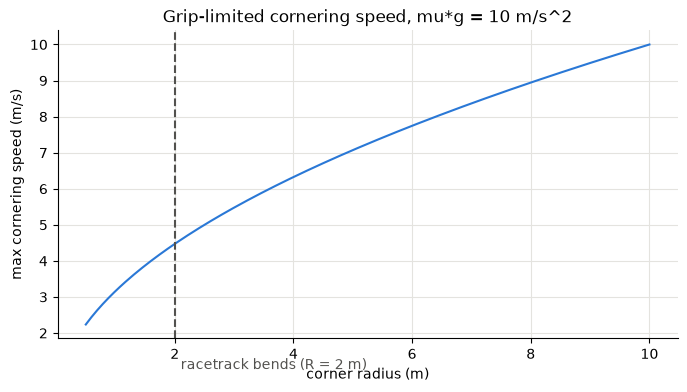

R = 2 m: v_max = 4.47 m/s


In [4]:
mu_g = 10.0
R = np.linspace(0.5, 10, 200)
plt.plot(R, np.sqrt(mu_g*R), color=BLUE)
plt.axvline(2.0, color=GREY, ls='--'); plt.text(2.1, 1, 'racetrack bends (R = 2 m)', color=GREY)
plt.xlabel('corner radius (m)'); plt.ylabel('max cornering speed (m/s)')
plt.title('Grip-limited cornering speed, mu*g = 10 m/s^2'); plt.show()
print(f"R = 2 m: v_max = {np.sqrt(mu_g*2):.2f} m/s")

## 4. System identification from the Gazebo drive
The drive (`saurcon_rl/sysid.py`) commanded full acceleration, braking, a steering step, and a
grid of constant speed x steering holds, while recording true pose at 50 Hz.

In [5]:
import csv
rows = np.array([[float(v) for v in r] for r in list(csv.reader(open('../data/sysid.csv')))[1:]])
t, cmd_v, cmd_steer, x, y, yaw = rows[np.unique(rows[:, 0], return_index=True)[1]].T
dt = np.diff(t); tm = t[1:]
speed = np.convolve(np.hypot(np.diff(x), np.diff(y))/dt, np.ones(5)/5, 'same')
yaw_rate = np.convolve(np.diff(np.unwrap(yaw))/dt, np.ones(5)/5, 'same')
cv, cs = cmd_v[1:], cmd_steer[1:]
print(len(t), 'samples over', round(t[-1]-t[0]), 's')

7585 samples over 152 s


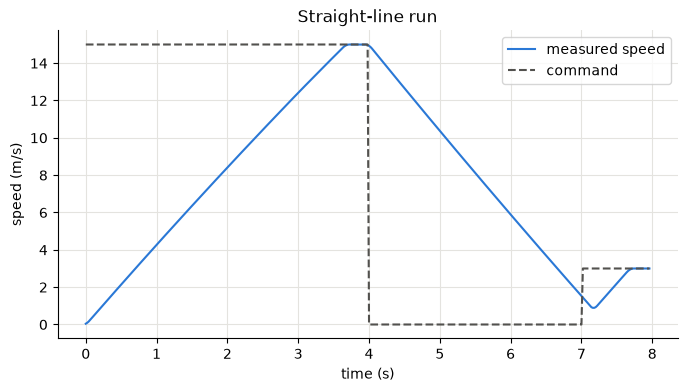

acceleration 4.11 m/s^2, braking -4.48 m/s^2


In [6]:
# Acceleration and braking: fit straight lines to speed vs time.
acc = (cv == 15) & (speed > 0.5) & (speed < 14)
i_end = np.where(cv == 15)[0][-1]
brk = (cv == 0) & (tm > tm[i_end]) & (tm < tm[i_end] + 3) & (speed > 1)
a_fit = np.polyfit(tm[acc], speed[acc], 1)[0]; b_fit = np.polyfit(tm[brk], speed[brk], 1)[0]
win = (tm > tm[acc][0] - 1) & (tm < tm[i_end] + 4)
plt.plot(tm[win] - tm[win][0], speed[win], color=BLUE, label='measured speed')
plt.plot(tm[win] - tm[win][0], cv[win], color=GREY, ls='--', label='command')
plt.xlabel('time (s)'); plt.ylabel('speed (m/s)'); plt.legend(); plt.title('Straight-line run'); plt.show()
print(f"acceleration {a_fit:.2f} m/s^2, braking {b_fit:.2f} m/s^2")

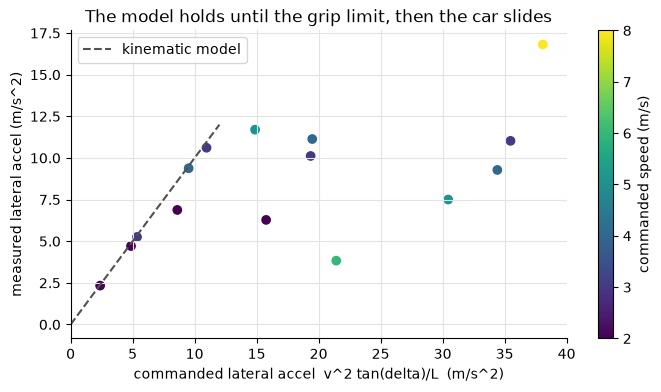

sliding plateau: median measured lateral acceleration 9.8 m/s^2 (quartiles 7.5-11.4); spin-outs scatter above it


In [7]:
# Steady-state cornering: measured lateral acceleration vs the kinematic prediction.
pts = []
for v in np.unique(cv[cs > 0]):
    for s in np.unique(cs[cs > 0]):
        idx = np.where((cv == v) & (cs == s))[0]
        if len(idx) < 20: continue
        q = idx[len(idx)//2:]                          # second half: steady state
        va, ra = np.median(speed[q]), np.median(np.abs(yaw_rate[q]))
        pts.append((v, s, v**2*np.tan(s)/L, va*ra))
pts = np.array(pts)
plt.scatter(pts[:, 2], pts[:, 3], c=pts[:, 0], cmap='viridis')
lim = np.linspace(0, 12, 2); plt.plot(lim, lim, color=GREY, ls='--', label='kinematic model')
plt.xlim(0, 40); plt.xlabel('commanded lateral accel  v^2 tan(delta)/L  (m/s^2)')
plt.ylabel('measured lateral accel (m/s^2)'); plt.colorbar(label='commanded speed (m/s)')
plt.legend(); plt.title('The model holds until the grip limit, then the car slides'); plt.show()
sat = pts[pts[:, 2] > 15, 3]          # commanded well beyond grip: the car slides at its limit
print(f"sliding plateau: median measured lateral acceleration {np.median(sat):.1f} m/s^2 "
      f"(quartiles {np.percentile(sat, 25):.1f}-{np.percentile(sat, 75):.1f}); spin-outs scatter above it")

## 5. Fitting the steering lag
Fit a first-order yaw-rate response $r(t) = r_{ss}(1-e^{-(t-t_0)/\tau})$ to the 0.3 rad step at 3 m/s.
Caveat: this step asks for $a_y \approx 10.8$ m/s², right at the grip limit, so the response is not purely
first-order and the fit is only approximate (the training environment randomises $\tau$ over 0.1–0.3 s).
Exercise 4 of chapter 1 asks you to design a better experiment.

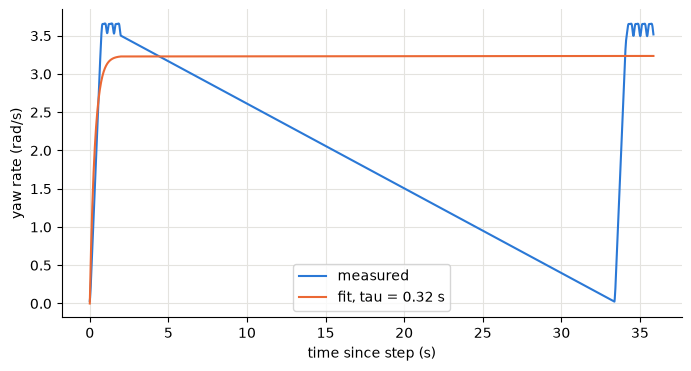

steady yaw rate 3.24 rad/s (kinematic 3.65), time constant 0.32 s


In [8]:
from scipy.optimize import curve_fit
idx = np.where((cv == 3) & (cs == 0.3))[0]
ts, rs = tm[idx] - tm[idx[0]], yaw_rate[idx]
model = lambda t, r_ss, tau: r_ss*(1 - np.exp(-np.clip(t, 0, None)/tau))
(r_ss, tau), _ = curve_fit(model, ts, rs, p0=(3, 0.2))
plt.plot(ts, rs, color=BLUE, label='measured'); plt.plot(ts, model(ts, r_ss, tau), color=ORANGE, label=f'fit, tau = {tau:.2f} s')
plt.xlabel('time since step (s)'); plt.ylabel('yaw rate (rad/s)'); plt.legend(); plt.show()
print(f"steady yaw rate {r_ss:.2f} rad/s (kinematic {3*np.tan(0.3)/L:.2f}), time constant {tau:.2f} s")

## Exercises
1. Re-fit acceleration using only the first second of the run. Is the ramp linear (rate-limited) or exponential (first-order)?
2. Add the friction limit to `simulate` (clip $a_y$) and find the steering step that first saturates at 5 m/s.
3. The training environment randomises grip in 8.5–10.5 m/s². Is that range justified by the scatter plot?